# NeuroPulse: LSTM-Based Synthetic ECG Signal Generation

**M.Sc. Data Science project | Google Colab notebook**

This notebook develops two LSTM experiments using the **MIT-BIH Arrhythmia Database, Record 100**:

1. **Experiment 1 – Continuous ECG next-step prediction and autoregressive continuation.**
2. **Experiment 2 – Normal-heartbeat extraction and sequence-to-sequence learning.**

The goal is to study whether LSTMs can learn sequential ECG patterns and generate signal continuations. Generated signals are experimental outputs, **not clinically validated ECGs** and must not be used for diagnosis.

**Dataset:** [MIT-BIH Arrhythmia Database](https://physionet.org/content/mitdb/1.0.0/)  
**Record:** `100` | **Sampling rate:** expected 360 Hz  
**Primary tools:** Python, WFDB, NumPy, SciPy, scikit-learn, TensorFlow/Keras, Matplotlib


## 1. Environment setup
Run this cell in Google Colab. If Colab asks for a runtime restart after installation, restart and run the notebook from the top.

In [1]:
!pip -q install wfdb scipy scikit-learn

In [2]:
import os
import random
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
import tensorflow as tf

from collections import Counter
from scipy.signal import butter, sosfiltfilt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout, TimeDistributed
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Python packages imported.")
print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

Python packages imported.
TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Download and load MIT-BIH Record 100

WFDB downloads the record and its annotations from PhysioNet. We use channel 0 for this initial experiment. Confirm the channel name and sampling frequency printed below.

In [3]:
record_name = "100"
record = wfdb.rdrecord(record_name, pn_dir="mitdb")
annotation = wfdb.rdann(record_name, "atr", pn_dir="mitdb")

sampling_rate = int(record.fs)
ecg_signal = record.p_signal[:, 0].astype(np.float32)
channel_name = record.sig_name[0]
duration_seconds = len(ecg_signal) / sampling_rate

print("Record:", record_name)
print("Channel:", channel_name)
print("Sampling rate:", sampling_rate, "Hz")
print("Number of channels in source:", record.n_sig)
print("Samples in selected channel:", len(ecg_signal))
print("Duration (seconds):", round(duration_seconds, 2))
print("Annotation count:", len(annotation.sample))

Record: 100
Channel: MLII
Sampling rate: 360 Hz
Number of channels in source: 2
Samples in selected channel: 650000
Duration (seconds): 1805.56
Annotation count: 2274


## 3. Exploratory data analysis (EDA)

ECG DATASET SUMMARY
---------------------------------------------
Minimum: -2.7149999141693115
Maximum: 1.434999942779541
Mean: -0.30629900097846985
Standard deviation: 0.1931995302438736
Median: -0.33500000834465027
Missing values: 0


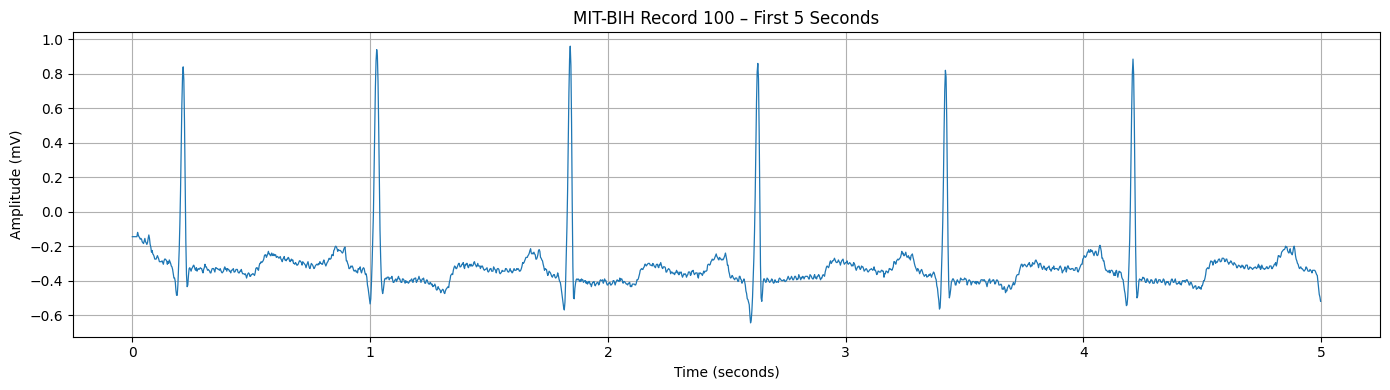

In [4]:
print("ECG DATASET SUMMARY")
print("-" * 45)
print("Minimum:", float(np.min(ecg_signal)))
print("Maximum:", float(np.max(ecg_signal)))
print("Mean:", float(np.mean(ecg_signal)))
print("Standard deviation:", float(np.std(ecg_signal)))
print("Median:", float(np.median(ecg_signal)))
print("Missing values:", int(np.isnan(ecg_signal).sum()))

seconds_to_plot = 5
n_plot = seconds_to_plot * sampling_rate
time_axis = np.arange(n_plot) / sampling_rate

plt.figure(figsize=(14, 4))
plt.plot(time_axis, ecg_signal[:n_plot], linewidth=0.9)
plt.title(f"MIT-BIH Record {record_name} – First {seconds_to_plot} Seconds")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.grid(True)
plt.tight_layout()
plt.show()

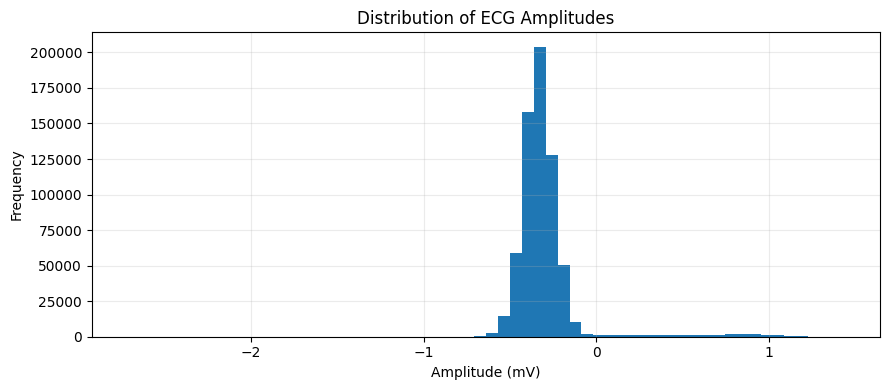

In [5]:
plt.figure(figsize=(9, 4))
plt.hist(ecg_signal, bins=60)
plt.title("Distribution of ECG Amplitudes")
plt.xlabel("Amplitude (mV)")
plt.ylabel("Frequency")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**EDA interpretation guide**

- The sampling rate tells us how many measurements are recorded per second.
- The amplitude histogram describes the distribution of signal values.
- Large positive or negative values should be inspected; do not automatically delete them because ECG peaks can be genuine signal features.
- ECG recordings are time series: the order of measurements matters.

## 4. Signal quality checks and filtering
We use a 0.5–40 Hz Butterworth bandpass as an exploratory preprocessing choice. Filtering can alter morphology; inspect the comparison and document the filter settings. To reduce boundary leakage, filter each chronological partition separately in the later split-based workflow.

Missing values: 0
Values above +1 mV: 2342
Values below -1 mV: 21


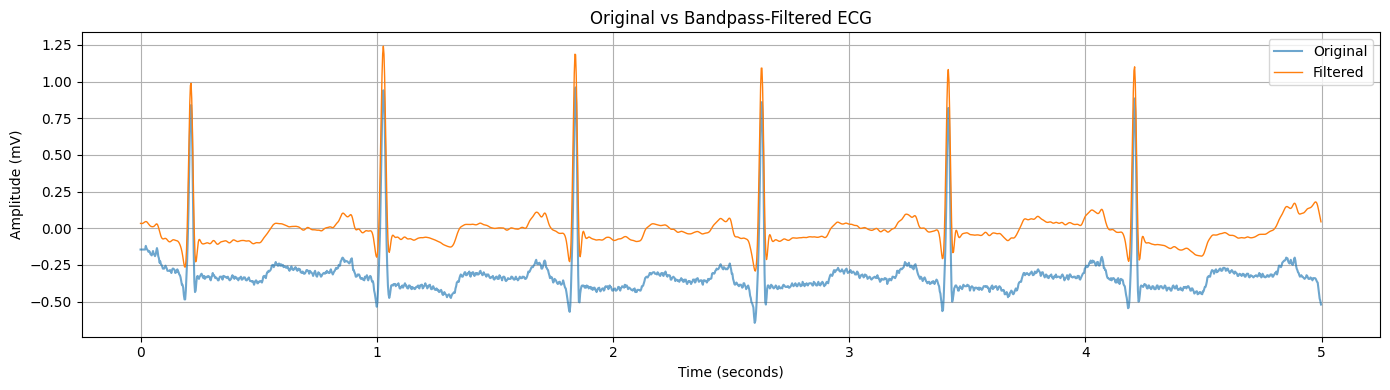

In [6]:
print("Missing values:", int(np.isnan(ecg_signal).sum()))
print("Values above +1 mV:", int(np.sum(ecg_signal > 1.0)))
print("Values below -1 mV:", int(np.sum(ecg_signal < -1.0)))

low_cutoff, high_cutoff = 0.5, 40.0
sos = butter(
    4,
    [low_cutoff, high_cutoff],
    btype="bandpass",
    fs=sampling_rate,
    output="sos"
)

# For EDA only: show filtering on a short portion.
# Later, filtering is performed independently within each split.
eda_filtered = sosfiltfilt(sos, ecg_signal[:n_plot])

plt.figure(figsize=(14, 4))
plt.plot(time_axis, ecg_signal[:n_plot], label="Original", alpha=0.65)
plt.plot(time_axis, eda_filtered, label="Filtered", linewidth=1.0)
plt.title("Original vs Bandpass-Filtered ECG")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 5. Experiment 1 – Continuous ECG LSTM

### 5.1 Chronological split, filtering and scaling

We split the raw recording chronologically into 70% training, 15% validation and 15% testing. Filtering is applied separately to each partition. The scaler is fitted on training data only to avoid using validation/test distribution information during fitting.

In [7]:
n_total = len(ecg_signal)
train_end = int(n_total * 0.70)
val_end = int(n_total * 0.85)

raw_train = ecg_signal[:train_end]
raw_val = ecg_signal[train_end:val_end]
raw_test = ecg_signal[val_end:]

train_filtered = sosfiltfilt(sos, raw_train).astype(np.float32)
val_filtered = sosfiltfilt(sos, raw_val).astype(np.float32)
test_filtered = sosfiltfilt(sos, raw_test).astype(np.float32)

continuous_scaler = MinMaxScaler()
train_norm = continuous_scaler.fit_transform(train_filtered.reshape(-1, 1)).ravel().astype(np.float32)
val_norm = continuous_scaler.transform(val_filtered.reshape(-1, 1)).ravel().astype(np.float32)
test_norm = continuous_scaler.transform(test_filtered.reshape(-1, 1)).ravel().astype(np.float32)

print("Train / validation / test samples:", len(train_norm), len(val_norm), len(test_norm))
print("Train range:", float(train_norm.min()), float(train_norm.max()))
print("Validation range:", float(val_norm.min()), float(val_norm.max()))
print("Test range:", float(test_norm.min()), float(test_norm.max()))

Train / validation / test samples: 455000 97500 97500
Train range: 0.0 1.0
Validation range: -0.357771635055542 0.9915871620178223
Test range: 0.24929805099964142 1.1499485969543457


### 5.2 Create sliding-window next-step sequences
Each input contains 180 previous samples; the target is the next sample. A stride of 10 reduces the number of highly overlapping training windows.

In [8]:
def make_next_step_sequences(data, seq_length=180, stride=10):
    n = (len(data) - seq_length - 1) // stride + 1
    X = np.empty((n, seq_length, 1), dtype=np.float32)
    y = np.empty((n,), dtype=np.float32)
    for j, start in enumerate(range(0, len(data) - seq_length, stride)):
        X[j, :, 0] = data[start:start + seq_length]
        y[j] = data[start + seq_length]
    return X, y

SEQ_LENGTH = 180
X_train, y_train = make_next_step_sequences(train_norm, SEQ_LENGTH, stride=10)
X_val, y_val = make_next_step_sequences(val_norm, SEQ_LENGTH, stride=10)
X_test, y_test = make_next_step_sequences(test_norm, SEQ_LENGTH, stride=10)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (45482, 180, 1) (45482,)
Validation: (9732, 180, 1) (9732,)
Test: (9732, 180, 1) (9732,)


### 5.3 Build and train the baseline LSTM

In [9]:
baseline_model = Sequential([
    Input(shape=(SEQ_LENGTH, 1)),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dense(16, activation="relu"),
    Dense(1)
])

baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 180, 64)        │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 180, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
callbacks = [
    EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5)
]

baseline_history = baseline_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=128,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/20
356/356 ━━━━━━━━━━━━━━━━━━━━ 19s 24ms/step - loss: 0.0048 - mae: 0.0323 - val_loss: 0.0025 - val_mae: 0.0196 - learning_rate: 0.0010
Epoch 2/20
356/356 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - loss: 0.0015 - mae: 0.0209 - val_loss: 7.5078e-04 - val_mae: 0.0165 - learning_rate: 0.0010
Epoch 3/20
356/356 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - loss: 4.2726e-04 - mae: 0.0127 - val_loss: 7.4994e-04 - val_mae: 0.0259 - learning_rate: 0.0010
Epoch 4/20
356/356 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - loss: 2.2453e-04 - mae: 0.0097 - val_loss: 1.1903e-04 - val_mae: 0.0071 - learning_rate: 0.0010
Epoch 5/20
356/356 ━━━━━━━━━━━━━━━━━━━━ 16s 21ms/step - loss: 1.4811e-04 - mae: 0.0078 - val_loss: 7.1572e-05 - val_mae: 0.0040 - learning_rate: 0.0010
Epoch 6/20
356/356 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - loss: 1.0294e-04 - mae: 0.0065 - val_loss: 4.6821e-05 - val_mae: 0.0035 - learning_rate: 0.0010
Epoch 7/20
356/356 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - loss: 7.7521e-05 - mae: 0.0057 - val_loss: 2.794

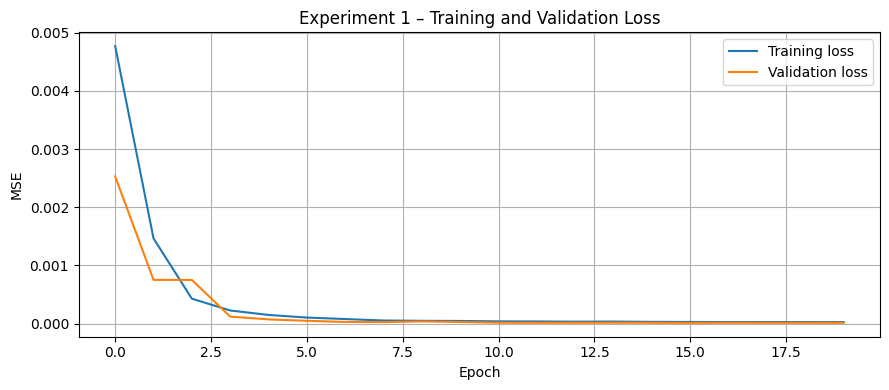

In [11]:
plt.figure(figsize=(9, 4))
plt.plot(baseline_history.history["loss"], label="Training loss")
plt.plot(baseline_history.history["val_loss"], label="Validation loss")
plt.title("Experiment 1 – Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### 5.4 Evaluate next-step prediction

Test MSE: 9.173292710329406e-06
Test MAE: 0.0013379491865634918


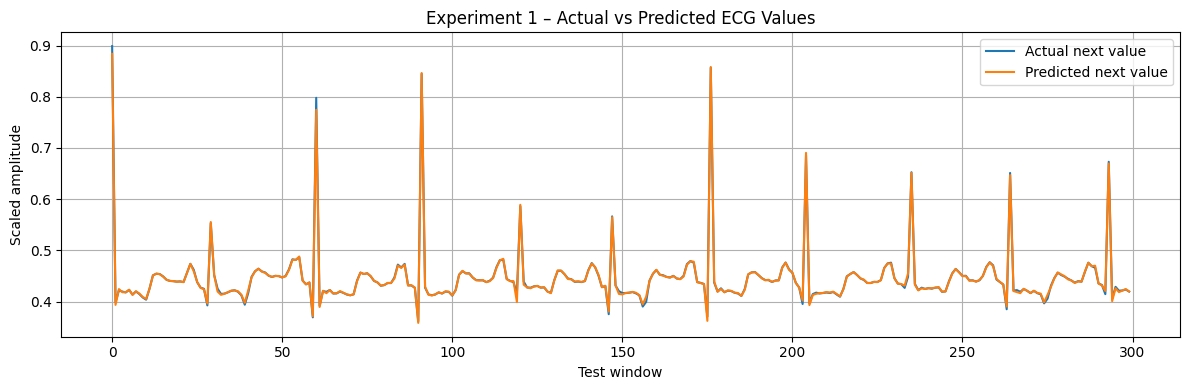

In [12]:
baseline_test_loss, baseline_test_mae = baseline_model.evaluate(X_test, y_test, verbose=0)
y_pred = baseline_model.predict(X_test[:1000], verbose=0).ravel()

print("Test MSE:", baseline_test_loss)
print("Test MAE:", baseline_test_mae)

plt.figure(figsize=(12, 4))
plt.plot(y_test[:300], label="Actual next value")
plt.plot(y_pred[:300], label="Predicted next value")
plt.title("Experiment 1 – Actual vs Predicted ECG Values")
plt.xlabel("Test window")
plt.ylabel("Scaled amplitude")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### 5.5 Autoregressive continuation

The function below repeatedly feeds each prediction back into the input window. This is a **conditional continuation** from a real seed segment, not an independently sampled or clinically realistic ECG. Long rollouts can drift because prediction errors accumulate.

Generated samples: 1800
Generated duration (s): 5.0
Scaled min/max: 0.36173418 0.88377726


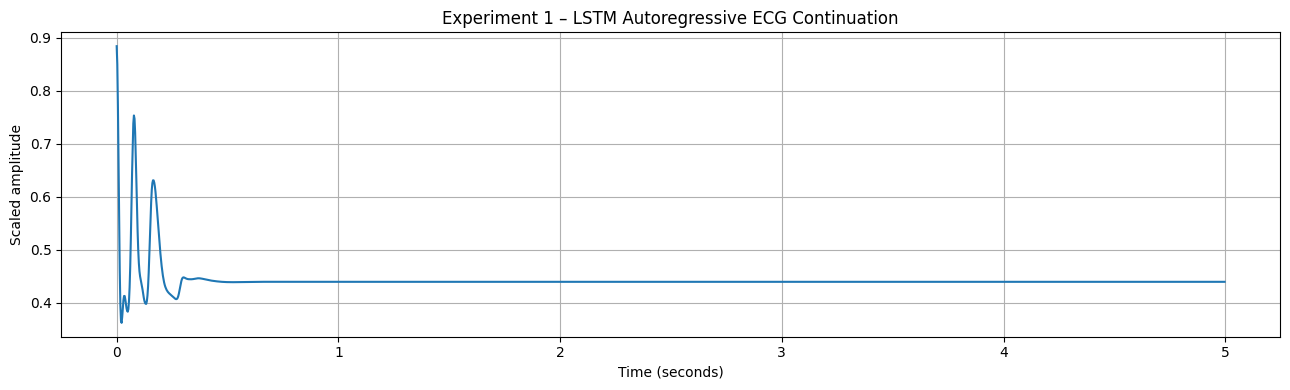

In [13]:
def generate_continuation(model, seed, n_steps, seq_length=180):
    current = np.asarray(seed, dtype=np.float32).reshape(-1).copy()
    if len(current) != seq_length:
        raise ValueError(f"Seed must contain exactly {seq_length} samples.")
    generated = []
    for _ in range(n_steps):
        pred = model.predict(current.reshape(1, seq_length, 1), verbose=0)[0, 0]
        generated.append(float(pred))
        current = np.concatenate([current[1:], np.array([pred], dtype=np.float32)])
    return np.asarray(generated, dtype=np.float32)

seed = test_norm[:SEQ_LENGTH].copy()
synthetic_continuation = generate_continuation(
    baseline_model, seed, n_steps=1800, seq_length=SEQ_LENGTH
)

synthetic_continuation_mV = continuous_scaler.inverse_transform(
    synthetic_continuation.reshape(-1, 1)
).ravel()

print("Generated samples:", len(synthetic_continuation))
print("Generated duration (s):", len(synthetic_continuation) / sampling_rate)
print("Scaled min/max:", synthetic_continuation.min(), synthetic_continuation.max())

plt.figure(figsize=(13, 4))
plt.plot(np.arange(len(synthetic_continuation)) / sampling_rate, synthetic_continuation)
plt.title("Experiment 1 – LSTM Autoregressive ECG Continuation")
plt.xlabel("Time (seconds)")
plt.ylabel("Scaled amplitude")
plt.grid(True)
plt.tight_layout()
plt.show()

## 6. Experiment 2 – Heartbeat-based ECG learning

We use the annotation file (`atr`) to locate normal beats (`N`). Each segment contains 0.2 seconds before and 0.4 seconds after the annotated beat location: 216 samples at 360 Hz.

**Important:** Record 100 is a single recording. The chronological partition below prevents segments from crossing partition boundaries, but results from one record are not a broad population-level validation.

In [14]:
annotation_counts = Counter(annotation.symbol)
print("Annotation symbol counts:")
for symbol, count in annotation_counts.items():
    print(repr(symbol), count)

normal_beats = np.asarray(annotation.sample)[
    np.asarray(annotation.symbol) == "N"
]
print("Normal beat annotations:", len(normal_beats))

Annotation symbol counts:
'+' 1
'N' 2239
'A' 33
'V' 1
Normal beat annotations: 2239


In [15]:
# Define the heartbeat window (Record 100 is expected to be sampled at 360 Hz)
pre_samples = int(0.2 * sampling_rate)
post_samples = int(0.4 * sampling_rate)
segment_length = pre_samples + post_samples

# Filtering was already applied independently to the three chronological partitions
# in Section 5.1. Extract each beat from its corresponding filtered partition.
heartbeat_train, heartbeat_val, heartbeat_test = [], [], []

for peak in normal_beats:
    start = int(peak - pre_samples)
    end = int(peak + post_samples)

    if start < 0 or end > len(ecg_signal):
        continue

    if end <= train_end:
        segment = train_filtered[start:end]
        heartbeat_train.append(segment)

    elif start >= train_end and end <= val_end:
        local_start = start - train_end
        local_end = end - train_end
        segment = val_filtered[local_start:local_end]
        heartbeat_val.append(segment)

    elif start >= val_end:
        local_start = start - val_end
        local_end = end - val_end
        segment = test_filtered[local_start:local_end]
        heartbeat_test.append(segment)

heartbeat_train = np.asarray(heartbeat_train, dtype=np.float32)
heartbeat_val = np.asarray(heartbeat_val, dtype=np.float32)
heartbeat_test = np.asarray(heartbeat_test, dtype=np.float32)

print("Heartbeat train:", heartbeat_train.shape)
print("Heartbeat validation:", heartbeat_val.shape)
print("Heartbeat test:", heartbeat_test.shape)
print("Segment length:", segment_length)

Heartbeat train: (1569, 216)
Heartbeat validation: (328, 216)
Heartbeat test: (339, 216)
Segment length: 216


### 6.1 Inspect extracted beats
Plot several training beats. The annotated beat location is at 0.2 seconds in each segment. The surrounding waveform may differ between beats.

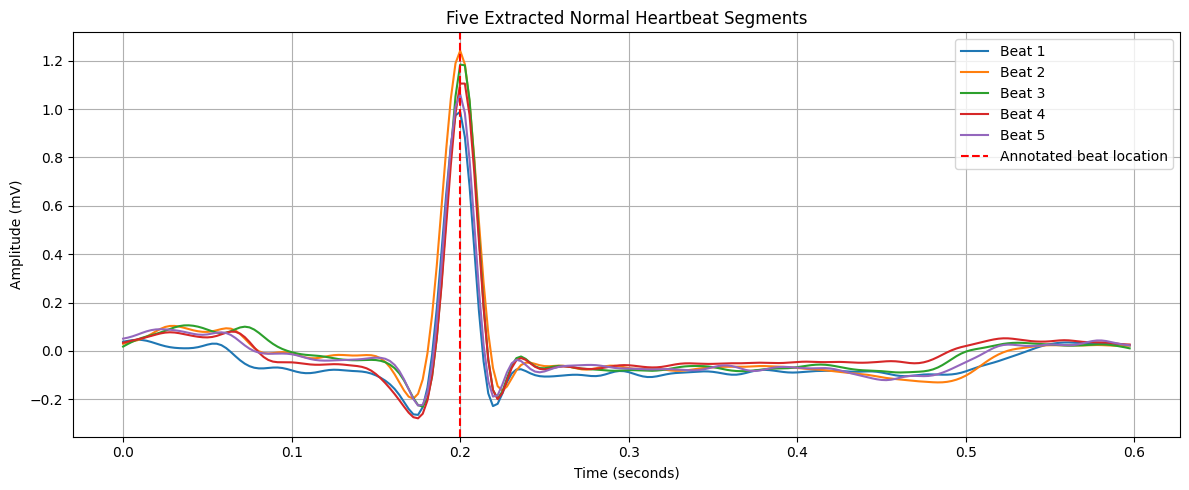

Train beat amplitude min/max: -0.3966720402240753 1.6926425695419312
Missing values: 0


In [16]:
if len(heartbeat_train) < 5:
    raise ValueError("Not enough training heartbeat segments were extracted.")

beat_time = np.arange(segment_length) / sampling_rate
plt.figure(figsize=(12, 5))
for i in range(5):
    plt.plot(beat_time, heartbeat_train[i], label=f"Beat {i+1}")
plt.axvline(0.2, color="red", linestyle="--", label="Annotated beat location")
plt.title("Five Extracted Normal Heartbeat Segments")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("Train beat amplitude min/max:",
      float(heartbeat_train.min()), float(heartbeat_train.max()))
print("Missing values:",
      int(np.isnan(heartbeat_train).sum() +
          np.isnan(heartbeat_val).sum() +
          np.isnan(heartbeat_test).sum()))

### 6.2 Normalize heartbeat segments

Fit the scaler using only training heartbeat samples. Validation and test samples are transformed with that fitted scaler. Values outside [0, 1] in validation/test are possible and should not be clipped automatically.

In [17]:
heartbeat_scaler = MinMaxScaler()

train_beats_norm = heartbeat_scaler.fit_transform(
    heartbeat_train.reshape(-1, 1)
).reshape(heartbeat_train.shape).astype(np.float32)

val_beats_norm = heartbeat_scaler.transform(
    heartbeat_val.reshape(-1, 1)
).reshape(heartbeat_val.shape).astype(np.float32)

test_beats_norm = heartbeat_scaler.transform(
    heartbeat_test.reshape(-1, 1)
).reshape(heartbeat_test.shape).astype(np.float32)

print("Train normalized:", train_beats_norm.shape,
      "range:", float(train_beats_norm.min()), float(train_beats_norm.max()))
print("Validation normalized:", val_beats_norm.shape,
      "range:", float(val_beats_norm.min()), float(val_beats_norm.max()))
print("Test normalized:", test_beats_norm.shape,
      "range:", float(test_beats_norm.min()), float(test_beats_norm.max()))

Train normalized: (1569, 216) range: 0.0 0.9999999403953552
Validation normalized: (328, 216) range: 0.04325394332408905 0.9876875281333923
Test normalized: (339, 216) range: -0.09866610169410706 0.9924882054328918


### 6.3 Prepare sequence-to-sequence data

For each 216-sample beat, the input is samples 0–214 and the target is samples 1–215. The model learns a one-sample-ahead mapping at every time step.

In [18]:
X_train_beat = train_beats_norm[:, :-1, np.newaxis]
y_train_beat = train_beats_norm[:, 1:, np.newaxis]

X_val_beat = val_beats_norm[:, :-1, np.newaxis]
y_val_beat = val_beats_norm[:, 1:, np.newaxis]

X_test_beat = test_beats_norm[:, :-1, np.newaxis]
y_test_beat = test_beats_norm[:, 1:, np.newaxis]

print("Train input/target:", X_train_beat.shape, y_train_beat.shape)
print("Validation input/target:", X_val_beat.shape, y_val_beat.shape)
print("Test input/target:", X_test_beat.shape, y_test_beat.shape)

Train input/target: (1569, 215, 1) (1569, 215, 1)
Validation input/target: (328, 215, 1) (328, 215, 1)
Test input/target: (339, 215, 1) (339, 215, 1)


### 6.4 Build and train sequence-to-sequence LSTM

In [19]:
heartbeat_model = Sequential([
    Input(shape=(segment_length - 1, 1)),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32, return_sequences=True),
    TimeDistributed(Dense(16, activation="relu")),
    TimeDistributed(Dense(1))
])

heartbeat_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

heartbeat_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 215, 64)        │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 215, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 215, 32)        │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 215, 16)        │           528 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 215, 1)         │            17 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
heartbeat_callbacks = [
    EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5)
]

heartbeat_history = heartbeat_model.fit(
    X_train_beat, y_train_beat,
    validation_data=(X_val_beat, y_val_beat),
    epochs=40,
    batch_size=32,
    callbacks=heartbeat_callbacks,
    verbose=1
)

Epoch 1/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 23s 148ms/step - loss: 0.0097 - mae: 0.0527 - val_loss: 0.0076 - val_mae: 0.0375 - learning_rate: 0.0010
Epoch 2/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - loss: 0.0047 - mae: 0.0351 - val_loss: 0.0031 - val_mae: 0.0310 - learning_rate: 0.0010
Epoch 3/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - loss: 0.0019 - mae: 0.0244 - val_loss: 0.0012 - val_mae: 0.0169 - learning_rate: 0.0010
Epoch 4/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 69ms/step - loss: 9.5061e-04 - mae: 0.0175 - val_loss: 6.2498e-04 - val_mae: 0.0125 - learning_rate: 0.0010
Epoch 5/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - loss: 5.7053e-04 - mae: 0.0143 - val_loss: 4.4133e-04 - val_mae: 0.0129 - learning_rate: 0.0010
Epoch 6/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 52ms/step - loss: 3.7639e-04 - mae: 0.0121 - val_loss: 2.1786e-04 - val_mae: 0.0080 - learning_rate: 0.0010
Epoch 7/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - loss: 2.6442e-04 - mae: 0.0099 - val_loss: 4.4129e-04 - val_mae: 0.0171 - l

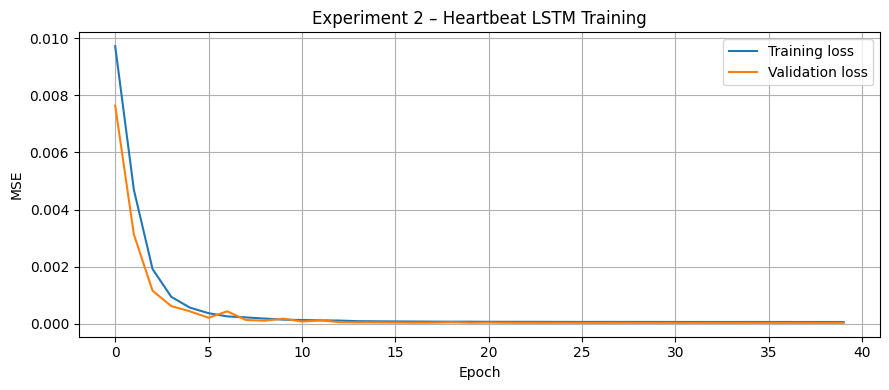

In [21]:
plt.figure(figsize=(9, 4))
plt.plot(heartbeat_history.history["loss"], label="Training loss")
plt.plot(heartbeat_history.history["val_loss"], label="Validation loss")
plt.title("Experiment 2 – Heartbeat LSTM Training")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### 6.5 Evaluate sequence prediction

Heartbeat test MSE: 4.5786931877955794e-05
Heartbeat test MAE: 0.0030150869861245155


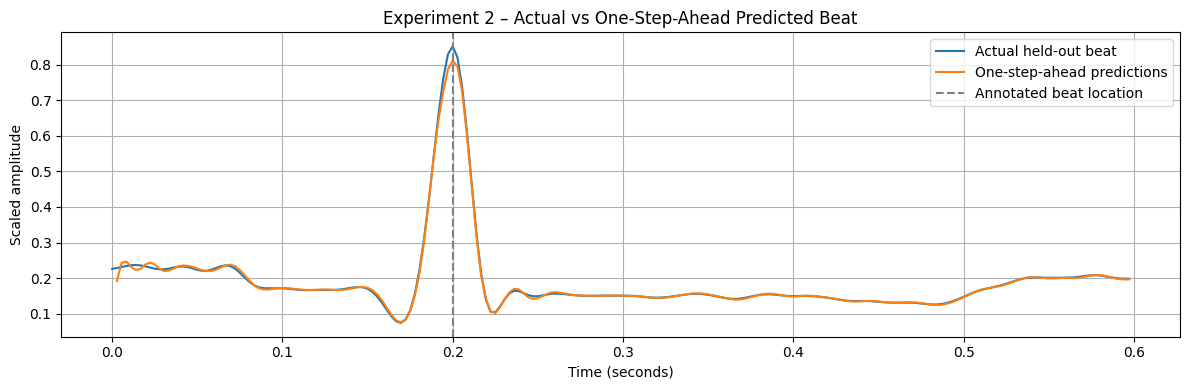

In [22]:
beat_test_loss, beat_test_mae = heartbeat_model.evaluate(
    X_test_beat, y_test_beat, verbose=0
)
print("Heartbeat test MSE:", beat_test_loss)
print("Heartbeat test MAE:", beat_test_mae)

# Visualize teacher-forced predictions for one held-out beat.
beat_index = 0
actual_beat = test_beats_norm[beat_index]
predicted_next = heartbeat_model.predict(
    X_test_beat[beat_index:beat_index+1], verbose=0
)[0, :, 0]

plt.figure(figsize=(12, 4))
plt.plot(np.arange(segment_length) / sampling_rate, actual_beat,
         label="Actual held-out beat")
plt.plot(np.arange(1, segment_length) / sampling_rate, predicted_next,
         label="One-step-ahead predictions")
plt.axvline(0.2, color="gray", linestyle="--", label="Annotated beat location")
plt.title("Experiment 2 – Actual vs One-Step-Ahead Predicted Beat")
plt.xlabel("Time (seconds)")
plt.ylabel("Scaled amplitude")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### 6.6 Autoregressive heartbeat continuation

This demonstration uses a prefix from a held-out beat as a seed and generates the remaining samples iteratively. It is a **conditional continuation**, not an independent synthetic heartbeat. The model is trained with teacher-forced sequence targets, so autoregressive performance may be worse than the one-step-ahead evaluation.

The first `seed_length` samples are copied from the held-out beat; the generated portion is model output.

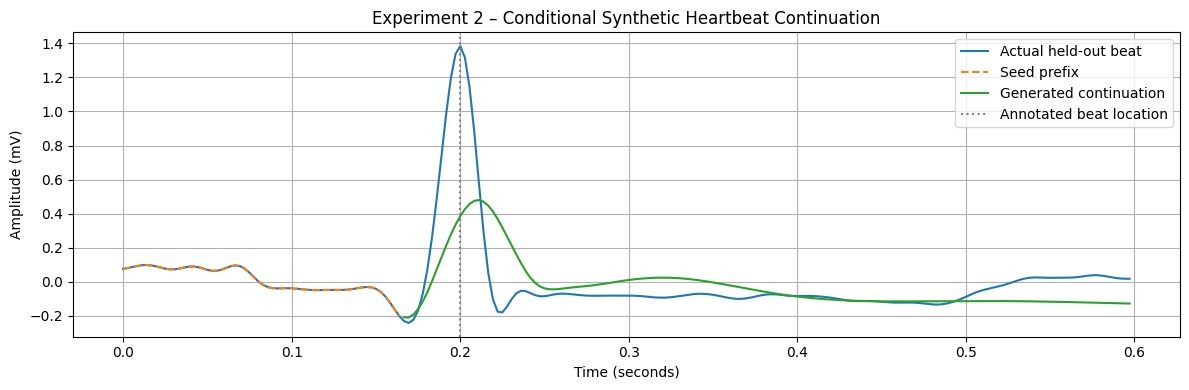

Generated segment length: 216
Generated normalized range: 0.08956063538789749 0.4195402264595032


In [23]:
def generate_heartbeat_continuation(model, seed_prefix, total_length=216):
    seed_prefix = np.asarray(seed_prefix, dtype=np.float32).reshape(-1)
    if not 1 <= len(seed_prefix) < total_length:
        raise ValueError("Seed prefix must be between 1 and total_length-1.")

    generated = list(seed_prefix)
    while len(generated) < total_length:
        # Model accepts fixed length 215. Use the most recent 215 values;
        # left-pad with the first seed value until enough context exists.
        context = np.asarray(generated[-215:], dtype=np.float32)
        if len(context) < 215:
            context = np.pad(context, (215 - len(context), 0),
                             mode="constant", constant_values=float(seed_prefix[0]))
        prediction_sequence = model.predict(
            context.reshape(1, 215, 1), verbose=0
        )[0, :, 0]
        next_value = float(prediction_sequence[-1])
        generated.append(next_value)

    return np.asarray(generated[:total_length], dtype=np.float32)

seed_length = 60
heldout_seed = test_beats_norm[0, :seed_length]
generated_beat_norm = generate_heartbeat_continuation(
    heartbeat_model, heldout_seed, total_length=segment_length
)

generated_beat_mV = heartbeat_scaler.inverse_transform(
    generated_beat_norm.reshape(-1, 1)
).ravel()

actual_beat_mV = test_beats_norm[0]
actual_beat_mV = heartbeat_scaler.inverse_transform(
    actual_beat_mV.reshape(-1, 1)
).ravel()

plt.figure(figsize=(12, 4))
plt.plot(beat_time, actual_beat_mV, label="Actual held-out beat")
plt.plot(beat_time[:seed_length], generated_beat_mV[:seed_length],
         linestyle="--", label="Seed prefix")
plt.plot(beat_time[seed_length:], generated_beat_mV[seed_length:],
         label="Generated continuation")
plt.axvline(0.2, color="gray", linestyle=":", label="Annotated beat location")
plt.title("Experiment 2 – Conditional Synthetic Heartbeat Continuation")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("Generated segment length:", len(generated_beat_norm))
print("Generated normalized range:",
      float(generated_beat_norm.min()), float(generated_beat_norm.max()))

## 7. Compare the two experiments

The models solve related but different tasks:

- Experiment 1 learns next-sample prediction from a continuous ECG recording and produces a long autoregressive continuation.
- Experiment 2 learns within-beat one-step-ahead mappings and demonstrates a conditional continuation from a beat prefix.

Do not compare their losses as if they were identical experiments: their target structures and data units differ.

In [24]:
comparison = pd.DataFrame([
    {
        "Experiment": "Continuous ECG LSTM",
        "Test MSE": float(baseline_test_loss),
        "Test MAE": float(baseline_test_mae),
        "Task": "Next-sample prediction"
    },
    {
        "Experiment": "Heartbeat sequence LSTM",
        "Test MSE": float(beat_test_loss),
        "Test MAE": float(beat_test_mae),
        "Task": "Within-beat next-sample sequence prediction"
    }
])
display(comparison)

,Experiment,Test MSE,Test MAE,Task
0,Continuous ECG LSTM,0.000009,0.001338,Next-sample prediction
1,Heartbeat sequence LSTM,0.000046,0.003015,Within-beat next-sample sequence prediction


## 8. Save outputs and models
Create a local output folder. In Colab, download the files from the Files pane or package them into a ZIP. The dataset itself is not copied into the project.

In [25]:
os.makedirs("neuropulse_outputs", exist_ok=True)
os.makedirs("neuropulse_models", exist_ok=True)

# Save generated continuous continuation
pd.DataFrame({
    "sample": np.arange(len(synthetic_continuation)),
    "time_seconds": np.arange(len(synthetic_continuation)) / sampling_rate,
    "synthetic_scaled": synthetic_continuation,
    "synthetic_amplitude_mV": synthetic_continuation_mV
}).to_csv("neuropulse_outputs/continuous_ecg_continuation.csv", index=False)

# Save heartbeat continuation
pd.DataFrame({
    "sample": np.arange(len(generated_beat_norm)),
    "time_seconds": beat_time,
    "synthetic_scaled": generated_beat_norm,
    "synthetic_amplitude_mV": generated_beat_mV
}).to_csv("neuropulse_outputs/heartbeat_continuation.csv", index=False)

baseline_model.save("neuropulse_models/continuous_lstm.keras")
heartbeat_model.save("neuropulse_models/heartbeat_lstm.keras")

with open("neuropulse_outputs/evaluation_summary.json", "w") as f:
    json.dump({
        "record": record_name,
        "sampling_rate_hz": sampling_rate,
        "continuous_test_mse": float(baseline_test_loss),
        "continuous_test_mae": float(baseline_test_mae),
        "heartbeat_test_mse": float(beat_test_loss),
        "heartbeat_test_mae": float(beat_test_mae)
    }, f, indent=2)

print("Outputs and models saved.")

Outputs and models saved.


## 9. Conclusion template

Complete this section after reviewing your actual outputs:

1. **Dataset:** MIT-BIH Record 100, selected channel and sampling rate.
2. **Preprocessing:** Bandpass filter, chronological partitioning and training-only scaling.
3. **Experiment 1:** Describe next-sample test metrics and the stability of its autoregressive continuation.
4. **Experiment 2:** Describe extracted normal beat count, sequence model metrics and conditional continuation quality.
5. **Comparison:** Discuss differences without assuming one experiment is superior unless supported by evidence.
6. **Limitations:** One record, limited beat diversity, annotation dependence, filtering effects, teacher-forcing exposure bias and autoregressive drift.
7. **Future work:** Multiple records and subjects, more diverse beat classes, robust morphology metrics, alternative generative models and independent validation.

**Safety statement:** NeuroPulse is an educational research prototype. Synthetic outputs are not diagnostic signals and are not intended for clinical use.

## 10. References

- Moody, G. B., & Mark, R. G. (2001). The impact of the MIT-BIH Arrhythmia Database. *IEEE Engineering in Medicine and Biology Magazine*, 20(3), 45–50.
- MIT-BIH Arrhythmia Database, PhysioNet: https://physionet.org/content/mitdb/1.0.0/
- WFDB Python package documentation: https://wfdb.readthedocs.io/
- TensorFlow/Keras documentation: https://www.tensorflow.org/guide/keras

**Reproducibility note:** Record the date the notebook was run, package versions, random seed, selected record/channel, preprocessing parameters and training configuration in your final report.